# **Day 42: Object Oriented Programming (Part 2) - Constructor, Methods and Magic Methods**

## **The Constructor (__init__) in Detail**
The constructor `__init__` is used to give the **starting data** to a new object. It can also have **default values**, just like normal functions.

In [1]:
class Hotel:
    def __init__(self, name, city, rooms, rate=2000):
        print(f"Creating {name}...")
        self.name = name
        self.city = city
        self.rooms = rooms
        self.rate = rate
        self.booked = 0

h = Hotel("Hotel Snow View", "Darjeeling", 20, rate=3500)
print(h.name, h.rate)

Creating Hotel Snow View...
Hotel Snow View 3500


## **Methods That Change the Object's Data**

In [2]:
class Hotel:
    def __init__(self, name, city, rooms, rate=2000):
        self.name = name
        self.city = city
        self.rooms = rooms
        self.rate = rate
        self.booked = 0
        self.guests = []

    def available(self):
        return self.rooms - self.booked

    def book(self, guest, n=1):
        if n > self.available():
            print(f"Sorry {guest}, only {self.available()} rooms left")
            return False
        self.booked += n
        self.guests.append((guest, n))
        print(f"{guest} booked {n} room(s) at {self.name}")
        return True

    def checkout(self, guest):
        for g in self.guests:
            if g[0] == guest:
                self.guests.remove(g)
                self.booked -= g[1]
                print(f"{guest} checked out")
                return
        print(f"{guest} not found")

    def income_per_night(self):
        return self.booked * self.rate

In [3]:
h = Hotel("Hotel Snow View", "Darjeeling", 5, rate=3500)
h.book("Das family", 2)
h.book("Roy family", 2)
h.book("Sen family", 3)
print("Rooms available:", h.available())

h.checkout("Das family")
h.book("Sen family", 3)
print("Income per night: Rs", h.income_per_night())

Das family booked 2 room(s) at Hotel Snow View
Roy family booked 2 room(s) at Hotel Snow View
Sorry Sen family, only 1 rooms left
Rooms available: 1
Das family checked out
Sen family booked 3 room(s) at Hotel Snow View
Income per night: Rs 17500


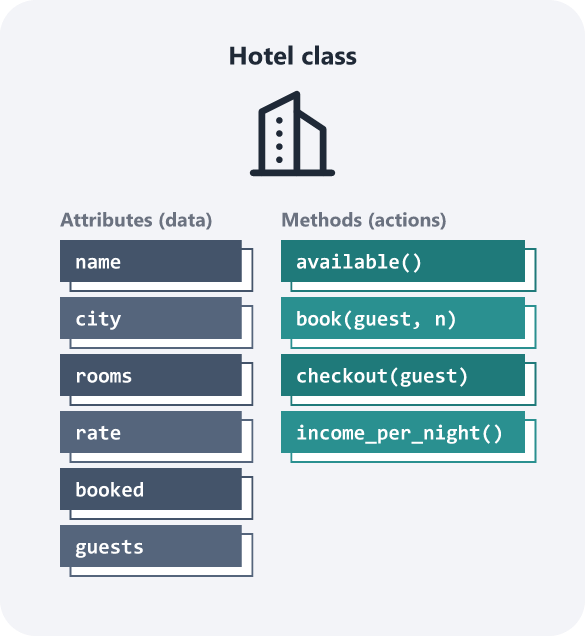

## **Magic Methods (a.k.a Dunder Methods)**
**Magic methods** are special methods whose names start and end with **double underscores**, like `__init__`. That is why they are also called **dunder** (double underscore) methods.

We do not call them directly. Python calls them **automatically** in certain situations.

**Common Magic Methods:**
1. **`__init__(self, ...)`**: Called when a new object is created.
2. **`__str__(self)`**: Called by `print()` and `str()`. It gives a nice, readable text for the object.
3. **`__repr__(self)`**: Gives a text for programmers. It is shown when we just type the object's name or put it in a list.
4. **`__len__(self)`**: Called by `len()`.

In [4]:
# Without __str__, printing an object shows something unclear
class PlaceOld:
    def __init__(self, name, district):
        self.name = name
        self.district = district

print(PlaceOld("Bishnupur", "Bankura"))

In [5]:
class Place:
    def __init__(self, name, district):
        self.name = name
        self.district = district

    def __str__(self):
        return f"{self.name}, {self.district}"

    def __repr__(self):
        return f"Place({self.name!r}, {self.district!r})"

p = Place("Bishnupur", "Bankura")
print(p)                                             # Uses __str__
print([p, Place("Mukutmanipur", "Bankura")])         # A list uses __repr__

Bishnupur, Bankura
[Place('Bishnupur', 'Bankura'), Place('Mukutmanipur', 'Bankura')]


## **Example from GIS: A Point Class**
In GIS, the simplest map object is a **Point**. Let us build a Point class with:
- a nice `__str__` to print it
- a method to find the **distance** to another point
- a method to turn it into **GeoJSON**

In [6]:
import math

class Point:
    """A location on the Earth given by latitude and longitude."""

    def __init__(self, name, lat, lon):
        self.name = name
        self.lat = lat
        self.lon = lon

    def __str__(self):
        return f"{self.name} ({self.lat:.4f}, {self.lon:.4f})"

    def distance_to(self, other):
        """Great-circle distance in km (Haversine formula)."""
        R = 6371
        p1, p2 = math.radians(self.lat), math.radians(other.lat)
        dp = p2 - p1
        dl = math.radians(other.lon - self.lon)
        a = math.sin(dp / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dl / 2) ** 2
        return 2 * R * math.asin(math.sqrt(a))

    def to_geojson(self):
        return {"type": "Feature",
                "geometry": {"type": "Point", "coordinates": [self.lon, self.lat]},
                "properties": {"name": self.name}}

In [7]:
kolkata = Point("Kolkata", 22.5726, 88.3639)
siliguri = Point("Siliguri", 26.7271, 88.3953)
digha = Point("Digha", 21.6266, 87.5074)

print(kolkata)
print(f"Kolkata to Siliguri: {kolkata.distance_to(siliguri):.1f} km")
print(f"Kolkata to Digha: {kolkata.distance_to(digha):.1f} km")
print(digha.to_geojson())

Kolkata (22.5726, 88.3639)
Kolkata to Siliguri: 462.0 km
Kolkata to Digha: 137.3 km
{'type': 'Feature', 'geometry': {'type': 'Point', 'coordinates': [87.5074, 21.6266]}, 'properties': {'name': 'Digha'}}


Let us understand the code above:
- `distance_to(self, other)`: The method takes **another Point object** as input. `self` is the first point and `other` is the second point.
- `kolkata.distance_to(siliguri)`: Inside the method, `self` is `kolkata` and `other` is `siliguri`.

## **Methods That Return self (Chaining)**
If a method returns `self`, we can call many methods one after another in one line.

In [8]:
class Order:
    def __init__(self):
        self.items = []

    def add(self, item, price):
        self.items.append((item, price))
        return self

    def total(self):
        return sum(p for _, p in self.items)

o = Order().add("Kosha mangsho", 220).add("Luchi (4)", 40).add("Mishti doi", 45)
print(o.items)
print("Total:", o.total())

[('Kosha mangsho', 220), ('Luchi (4)', 40), ('Mishti doi', 45)]
Total: 305


## **Practice Problem: A Simple Bank Account**

In [9]:
class Account:
    def __init__(self, holder, balance=0):
        self.holder = holder
        self.balance = balance
        self.history = []

    def deposit(self, amount):
        self.balance += amount
        self.history.append(("Deposit", amount))

    def withdraw(self, amount):
        if amount > self.balance:
            print("Insufficient balance")
            return
        self.balance -= amount
        self.history.append(("Withdraw", amount))

    def __str__(self):
        return f"{self.holder}: Rs {self.balance}"

acc = Account("Tapas Maity")
acc.deposit(5000)
acc.withdraw(1200)
acc.withdraw(10000)
print(acc)
print(acc.history)

Insufficient balance
Tapas Maity: Rs 3800
[('Deposit', 5000), ('Withdraw', 1200)]


In [10]:
# Quick question
# What will print(x) show?
# class Box:
#     def __init__(self, v):
#         self.v = v
#     def __str__(self):
#         return f"Box of {self.v}"
# x = Box(7)
# print(x)